# Линейная алгебра для ML — домашнее задание

**Автор:** _имя_ · **Модуль:** математика для ML, тема 1

Как устроено каждое задание:

1. **Вручную** — расчёт с числами в markdown: формула → подстановка → ответ.
2. **Код** — свои функции на чистом Python, без готовых функций NumPy.
3. **Проверка NumPy** — тот же расчёт через NumPy и сравнение через `check()`.
4. **Визуализация** — там, где её просят.
5. **Вывод** — 2–4 предложения своими словами.

In [30]:
import math

import numpy as np
import matplotlib.pyplot as plt

## 0. Функции

Здесь живут функции, которые используются в нескольких заданиях (требование задания 6). Добавляй их по мере необходимости: первые появятся в задании 1.

In [31]:
def dot(a, b):
    total = 0
    for x, y in zip(a, b):
        total += x * y
    return total


## 1. Векторы

Векторы $a = [2, 1]$ и $b = [1, 3]$.

- найди $a + b$, $a - b$, $2a - 3b$ и скалярное произведение $a \cdot b$
- вычисли длину каждого вектора и угол между ними
- проверь, являются ли векторы линейно независимыми
- изобрази $a$, $b$ и $a + b$ на одной координатной плоскости
- объясни, что означает скалярное произведение с точки зрения направления векторов

In [32]:
a = np.array([2, 1])
b = np.array([1, 3])

In [33]:
print(dot(a, b), np.dot(a, b))
# print(dot([1, 0], [-1, 0]))

5 5


### 1.1 Операции — вручную

_Распиши: формула → подстановка чисел → ответ. Например:_ $a + b = [2 + 1,\ 1 + 3] = [\,?,\ ?\,]$
Векторы $a = [2, 1]$ и $b = [1, 3]$.

a + b = [2 + 1, 1 + 3] = [3, 4]
a − b = [2 - 1, 1 - 3] = [1, -2]
2a − 3b = [4 - 3, 2 - 9] = [1, -7]
a · b = 2 * 1 + 1 * 3 = 2 + 3 = 5

In [34]:
print("a + b   =", a + b)
print("a - b   =", a - b)
print("2a - 3b =", 2 * a - 3 * b)
print("a · b   =", dot(a, b), "| NumPy:", a @ b)

a + b   = [3 4]
a - b   = [ 1 -2]
2a - 3b = [ 1 -7]
a · b   = 5 | NumPy: 5


### 1.2 Длины и угол — вручную

_Формулы:_ $\|a\| = \sqrt{a \cdot a}$, $\quad \cos\theta = \dfrac{a \cdot b}{\|a\|\,\|b\|}$

_Подставь числа:_

|a| = √(a·a) = √(2·2 + 1·1) = √5 ≈ 2,24
|b| = √(1 * 1 + 3 * 3) = √10 ≈ 3,16
cos θ = a·b / (|a|·|b|) = 5 / (√5 · √10) = 5 / √50 ≈ 5 / 7,07 ≈ 0,707
θ = arccos(0,707) = 45°

In [35]:
def norm(a):
    return math.sqrt(dot(a, a))         # длина = корень из dot вектора на самого себя

def angle_deg(a, b):
    cos = dot(a, b) / (norm(a) * norm(b))       # формула косинуса из пункта А
    return math.degrees(math.acos(cos))

print("|a| =", norm(a), "| NumPy:", np.linalg.norm(a))
print("|b| =", norm(b), "| NumPy:", np.linalg.norm(b))
print("угол =", angle_deg(a, b))

|a| = 2.23606797749979 | NumPy: 2.23606797749979
|b| = 3.1622776601683795 | NumPy: 3.1622776601683795
угол = 45.00000000000001


### 1.3 Линейная независимость — вручную

_Два вектора на плоскости независимы, если не лежат на одной прямой. Проверка: определитель матрицы, где $a$ и $b$ — столбцы, не равен нулю._

матрица: | 2  1 |
         | 1  3 |

det = 2·3 − 1·1 = 5
det ≠ 0 → векторы линейно независимы то есть не лежат на одной прямой

In [36]:
# TODO: свой определитель 2×2 и проверка через np.linalg.det или np.linalg.matrix_rank
def det2(a, b):
    return a[0] * b[1] - a[1] * b[0]     # a[0] — первая координата a, a[1] — вторая

M = np.column_stack([a, b])      # склеивает a и b в матрицу столбцами
print("det вручную:", det2(a, b), "| NumPy:", np.linalg.det(M))
print("ранг:", np.linalg.matrix_rank(M))

det вручную: 5 | NumPy: 5.000000000000001
ранг: 2


### 1.4 Рисунок

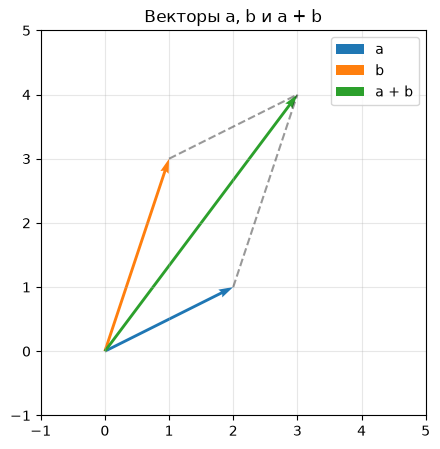

In [37]:
# TODO: a, b и a + b стрелками из начала координат (plt.quiver)
# подписи векторов, сетка, одинаковый масштаб осей

s = a + b                                   # вектор a + b

fig, ax = plt.subplots(figsize=(5, 5))

# стрелка из точки (0, 0) в точку (x, y)
ax.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='tab:blue', label='a')
ax.quiver(0, 0, b[0], b[1], angles='xy', scale_units='xy', scale=1, color='tab:orange', label='b')
ax.quiver(0, 0, a[0] + b[0], a[1] + b[1], angles='xy', scale_units='xy', scale=1, color='tab:green', label='a + b')

# пунктир — правило параллелограмма
ax.plot([a[0], s[0]], [a[1], s[1]], 'k--', alpha=0.4)
ax.plot([b[0], s[0]], [b[1], s[1]], 'k--', alpha=0.4)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect('equal')                      # одинаковый масштаб осей
ax.grid(alpha=0.3)
ax.legend()
ax.set_title('Векторы a, b и a + b')
plt.show()

### Мой вывод

_Ответь своими словами:_
- что значит, что $a \cdot b > 0$? Когда скалярное произведение равно нулю, а когда отрицательное?
- как скалярное произведение связано с углом между векторами?
- что даёт то, что $a$ и $b$ линейно независимы?

1. Скалярное произведение это число, по которому понятно смотрят ли две стрелки в одну сторону. У нас вышло 5 и это больше нуля, значит примерно в одну. При нуле стрелки были бы под прямым углом, при минусе смотрели бы в разные стороны.

2. Угол между ними 45°, это меньше 90°, косинус положительный, поэтому и скалярное произведение положительное 

3. Векторы не лежат на одной линии  и один нельзя получить из другого растяжением. Это и есть независимость. Определитель 5, а не ноль  и на графике параллелограмм не сплющен.

## 2. Матрицы и линейные преобразования

Матрицы $A = \begin{pmatrix} 2 & 1 \\ 1 & 3 \end{pmatrix}$ и $B = \begin{pmatrix} 1 & 2 \\ 0 & 1 \end{pmatrix}$.

- вычисли $A + B$, $AB$ и $BA$ и объясни, почему $AB$ и $BA$ могут отличаться
- примени обе матрицы к векторам $[1, 0]$ и $[0, 1]$
- нарисуй исходные и преобразованные базисные векторы
- опиши своими словами, как каждая матрица меняет пространство

_Разберём после задания 1._

A + B = [[2+1, 1+2], [1+0, 3+1]] = [[3, 3], [1, 4]]      ← просто поэлементно

AB, левый верхний элемент: строка 1 из A · столбец 1 из B = [2, 1] · [1, 0] = 2·1 + 1·0 = 2
AB = [[2, 5], [1, 5]]
BA = [[4, 7], [1, 3]]

In [38]:
# задание 2
def matmul(A, B):
    C = np.zeros((A.shape[0], B.shape[1]))
    for i in range(A.shape[0]):
        for j in range(B.shape[1]):
            C[i, j] = dot(A[i], B[:, j])
    return C
A = np.array([[2, 1], [1, 3]])
B = np.array([[1, 2], [0, 1]])
print("A + B =\n", A + B)
print("AB =\n", matmul(A, B), "\nNumPy:\n", A @ B)
print("BA =\n", matmul(B, A), "\nNumPy:\n", B @ A)

A + B =
 [[3 3]
 [1 4]]
AB =
 [[2. 5.]
 [1. 5.]] 
NumPy:
 [[2 5]
 [1 5]]
BA =
 [[4. 7.]
 [1. 3.]] 
NumPy:
 [[4 7]
 [1 3]]



A = [[2, 1], [1, 3]] и B = [[1, 2], [0, 1]]

примени обе матрицы к векторам [1, 0] и [0, 1]

A·[1,0] = [2·1 + 1·0, 1·1 + 3·0] = [2, 1]   ← 1-й столбец A
A·[0,1] = [2·0 + 1·1, 1·0 + 3·1] = [1, 3]   ← 2-й столбец A
B·[1,0] = [1·1 + 2·0, 0·1 + 1·0] = [1, 0]   ← 1-й столбец B
B·[0,1] = [1·0 + 2·1, 0·0 + 1·1] = [2, 1]   ← 2-й столбец B

A·e1 = [2 1] | NumPy: [2 1]
A·e2 = [1 3] | NumPy: [1 3]
B·e1 = [1 0] | NumPy: [1 0]
B·e2 = [2 1] | NumPy: [2 1]


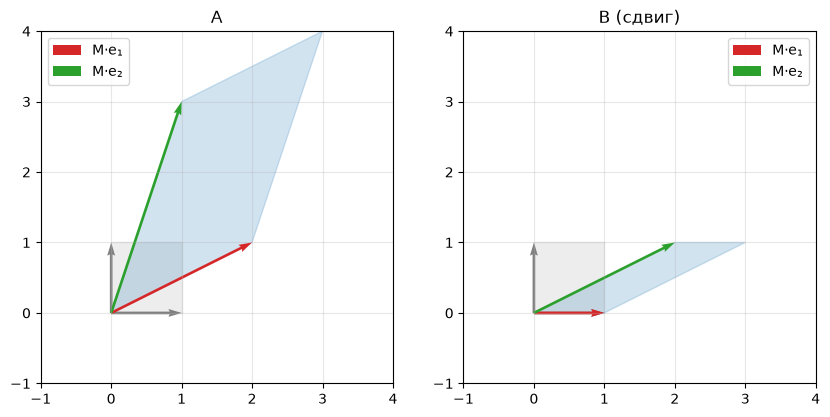

In [39]:
def matvec(M, v):
    """Матрица × вектор: каждая строка M скалярно на v."""
    return np.array([dot(row, v) for row in M])

def draw_basis(ax, M, title):
    """Рисует e1, e2 и квадрат до (серым) и после преобразования матрицей M."""
    e1, e2 = np.array([1, 0]), np.array([0, 1])
    Me1, Me2 = matvec(M, e1), matvec(M, e2)
    sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]])
    tsq = np.array([matvec(M, p) for p in sq])
    ax.fill(sq[:, 0], sq[:, 1], color='lightgray', alpha=0.4)
    ax.fill(tsq[:, 0], tsq[:, 1], color='tab:blue', alpha=0.2)
    ax.quiver(0, 0, 1, 0, angles='xy', scale_units='xy', scale=1, color='gray')
    ax.quiver(0, 0, 0, 1, angles='xy', scale_units='xy', scale=1, color='gray')
    ax.quiver(0, 0, Me1[0], Me1[1], angles='xy', scale_units='xy', scale=1, color='tab:red', label='M·e₁')
    ax.quiver(0, 0, Me2[0], Me2[1], angles='xy', scale_units='xy', scale=1, color='tab:green', label='M·e₂')
    ax.set_xlim(-1, 4); ax.set_ylim(-1, 4)
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend(); ax.set_title(title)

e1, e2 = np.array([1, 0]), np.array([0, 1])
for name, M in (("A", A), ("B", B)):
    print(f"{name}·e1 = {matvec(M, e1)} | NumPy: {M @ e1}")
    print(f"{name}·e2 = {matvec(M, e2)} | NumPy: {M @ e2}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_basis(axes[0], A, "A")
draw_basis(axes[1], B, "B (сдвиг)")
plt.show()

## 3. Определитель, обратная матрица и система уравнений

Для матрицы $A$:

- найди определитель и объясни его геометрический смысл
- определи, существует ли обратная матрица, и вычисли её
- реши систему $Ax = [5, 7]$ вручную и через `numpy.linalg.solve`
- проверь решение подстановкой: результат $Ax$ должен совпасть с $[5, 7]$
- придумай матрицу с нулевым определителем и объясни, что происходит с пространством после такого преобразования

_Разберём после задания 2._

det A = 2·3 − 1·1 = 5  → любая площадь после A становится в 5 раз больше

det ≠ 0 → обратная матрица есть. Формула 2×2: диагональ меняем местами,
у двух других чисел меняем знак, всё делим на det:
A⁻¹ = 1/5 · [[3, −1], [−1, 2]] = [[0.6, −0.2], [−0.2, 0.4]]

Система Ax = [5, 7]:   2x + y = 5,   x + 3y = 7
из первого: y = 5 − 2x  →  x + 3(5 − 2x) = 7  →  −5x = −8  →  x = 1.6,  y = 1.8

Проверка: [2·1.6 + 1.8,  1.6 + 3·1.8] = [5, 7] ✓

Матрица с det = 0:  S = [[1, 2], [0.5, 1]],  det = 1·1 − 2·0.5 = 0
второй столбец = первый × 2 → вся плоскость схлопывается в одну линию

det A = 5 | NumPy: 5.000000000000001
A⁻¹ =
 [[ 0.6 -0.2]
 [-0.2  0.4]] 
NumPy:
 [[ 0.6 -0.2]
 [-0.2  0.4]]
A · A⁻¹ =
 [[ 1.00000000e+00  0.00000000e+00]
 [-1.11022302e-16  1.00000000e+00]]
x = [1.6 1.8] | NumPy solve: [1.6 1.8]
проверка A·x = [5. 7.]
det S = 0.0


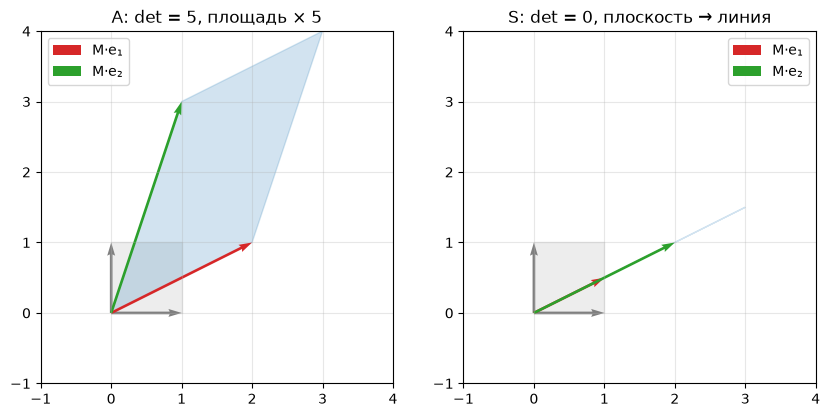

In [40]:
def inv2(M):
    """Обратная 2×2: диагональ местами, у остальных минус, делим на det."""
    (a, b), (c, d) = M
    det = a * d - b * c
    if det == 0:
        raise ValueError("det = 0: обратной матрицы нет")
    return np.array([[d, -b], [-c, a]]) / det

print("det A =", det2(A[:, 0], A[:, 1]), "| NumPy:", np.linalg.det(A))

A_inv = inv2(A)
print("A⁻¹ =\n", A_inv, "\nNumPy:\n", np.linalg.inv(A))
print("A · A⁻¹ =\n", matmul(A, A_inv))      # единичная матрица: «ничего не делает»

rhs = np.array([5, 7])
x = matvec(A_inv, rhs)
print("x =", x, "| NumPy solve:", np.linalg.solve(A, rhs))
print("проверка A·x =", matvec(A, x))

S = np.array([[1, 2], [0.5, 1]])
print("det S =", det2(S[:, 0], S[:, 1]))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_basis(axes[0], A, "A: det = 5, площадь × 5")
draw_basis(axes[1], S, "S: det = 0, плоскость → линия")
plt.show()

det A = 5: A увеличивает площадь в 5 раз, на графике это видно.
det ≠ 0, поэтому A⁻¹ существует; A · A⁻¹ = единичная матрица, то есть «сделали и отменили».
Система решена двумя способами, x = [1.6, 1.8], подстановка даёт [5, 7].
У S det = 0: квадрат сплющился в отрезок, плоскость стала линией. Обратной нет, потому что из линии уже не понять, где точка была раньше.

## 4. Базис и линейная зависимость

Наборы векторов $v_1 = [1, 0, 1]$, $v_2 = [0, 1, 1]$, $v_3 = [1, 1, 2]$ и $u = [3, 2]$.

- определи, являются ли $v_1, v_2, v_3$ линейно независимыми
- найди ранг матрицы, составленной из этих векторов
- вырази $u$ в базисе $e_1 = [1, 1]$, $e_2 = [1, -1]$
- восстанови исходный вектор из найденных координат и проверь результат

_Разберём после задания 3._

v1 + v2 = [1+0, 0+1, 1+1] = [1, 1, 2] = v3
→ v3 собирается из v1 и v2, значит векторы линейно ЗАВИСИМЫ

Ранг = 2: векторов три, а разных направлений только два
(все три лежат в одной плоскости)

u в базисе e1 = [1, 1], e2 = [1, −1]  (в коде назвал их f1, f2,
чтобы не путать со стандартными e1, e2 из задания 2)
ищем c1, c2:  c1·f1 + c2·f2 = u
  c1 + c2 = 3
  c1 − c2 = 2
складываем: 2·c1 = 5 → c1 = 2.5, c2 = 0.5

Проверка: 2.5·[1, 1] + 0.5·[1, −1] = [2.5 + 0.5, 2.5 − 0.5] = [3, 2] ✓

In [43]:
v1, v2, v3 = np.array([1, 0, 1]), np.array([0, 1, 1]), np.array([1, 1, 2])
V = np.column_stack([v1, v2, v3])
print("v1 + v2 =", v1 + v2, "| совпадает с v3:", np.array_equal(v1 + v2, v3))
print("det V =", np.linalg.det(V))
print("ранг V =", np.linalg.matrix_rank(V))

u = np.array([3, 2])
f1, f2 = np.array([1, 1]), np.array([1, -1])
F = np.column_stack([f1, f2])
c = matvec(inv2(F), u)                 # координаты u в новом базисе — своими функциями
print("координаты u в базисе f1, f2:", c, "| NumPy solve:", np.linalg.solve(F, u))
print("восстановили:", c[0] * f1 + c[1] * f2)

v1 + v2 = [1 1 2] | совпадает с v3: True
det V = 0.0
ранг V = 2
координаты u в базисе f1, f2: [2.5 0.5] | NumPy solve: [2.5 0.5]
восстановили: [3. 2.]


In [41]:
# задание 4

## 5. Собственные значения и собственные векторы

Для матрицы $C = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$:

- найди собственные значения и собственные векторы вручную
- проверь результат через `numpy.linalg.eig`
- для каждого собственного вектора проверь равенство $Cv = \lambda v$
- изобрази несколько произвольных векторов и собственные направления до и после преобразования
- объясни, почему собственные векторы не меняют направление после применения матрицы

_Разберём после задания 4._

Ищем λ, при которых det(C − λI) = 0:
(2 − λ)·(2 − λ) − 1·1 = 0  →  (2 − λ)² = 1  →  2 − λ = ±1  →  λ = 3 или λ = 1

λ = 3:  (2−3)x + y = 0  →  y = x  →  v = [1, 1]
λ = 1:  (2−1)x + y = 0  →  y = −x →  v = [1, −1]

Проверка:
C·[1, 1]  = [2+1, 1+2] = [3, 3]  = 3·[1, 1]   ✓
C·[1, −1] = [2−1, 1−2] = [1, −1] = 1·[1, −1]  ✓

λ вручную: [np.float64(3.0), np.float64(1.0)] | NumPy: [3.+0.j 1.+0.j]
векторы NumPy (столбцы):
 [[ 0.70710678+0.j -0.70710678+0.j]
 [ 0.70710678+0.j  0.70710678+0.j]]
λ = 3.0: C·v = [3. 3.], λ·v = [3. 3.], совпадают: True
λ = 1.0: C·v = [ 1. -1.], λ·v = [ 1. -1.], совпадают: True


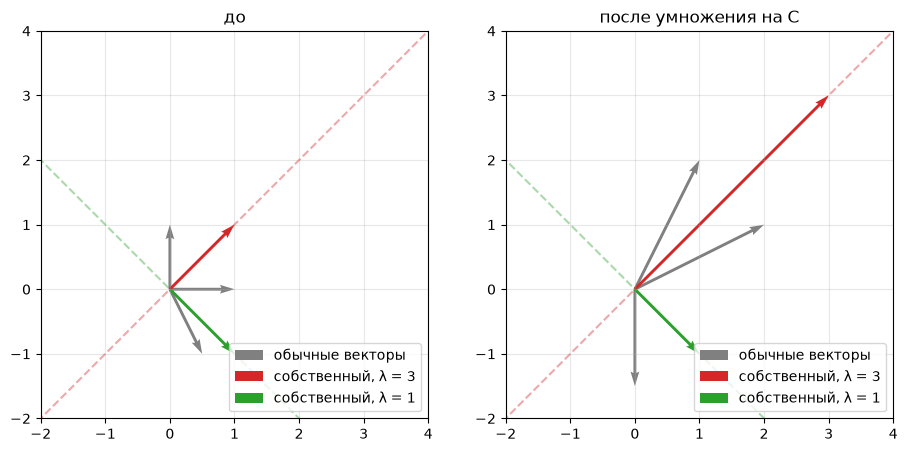

In [44]:
def eig2(M):
    """Собственные значения и векторы 2×2.
    λ — корни λ² − tr·λ + det = 0; вектор [b, λ − a] обнуляет первую строку (M − λI)."""
    (a, b), (c, d) = M
    tr, det = a + d, a * d - b * c
    root = math.sqrt(tr**2 - 4 * det)
    lams = [(tr + root) / 2, (tr - root) / 2]
    vecs = [np.array([b, lam - a]) for lam in lams]
    return lams, vecs

C = np.array([[2, 1], [1, 2]])
lams, vecs = eig2(C)
np_lams, np_vecs = np.linalg.eig(C)
print("λ вручную:", lams, "| NumPy:", np_lams)
print("векторы NumPy (столбцы):\n", np_vecs)
for lam, v in zip(lams, vecs):
    print(f"λ = {lam}: C·v = {matvec(C, v)}, λ·v = {lam * v}, совпадают: {np.allclose(matvec(C, v), lam * v)}")

others = [np.array([1, 0]), np.array([0, 1]), np.array([0.5, -1])]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, title, M in ((axes[0], "до", np.eye(2)), (axes[1], "после умножения на C", C)):
    for i, v in enumerate(others):
        w = matvec(M, v)
        ax.quiver(0, 0, w[0], w[1], angles='xy', scale_units='xy', scale=1,
                  color='gray', label='обычные векторы' if i == 0 else None)
    for v, lam, color in zip(vecs, lams, ('tab:red', 'tab:green')):
        w = matvec(M, v)
        ax.plot([-4 * v[0], 4 * v[0]], [-4 * v[1], 4 * v[1]], color=color, ls='--', alpha=0.4)
        ax.quiver(0, 0, w[0], w[1], angles='xy', scale_units='xy', scale=1,
                  color=color, label=f'собственный, λ = {lam:g}')
    ax.set_xlim(-2, 4); ax.set_ylim(-2, 4)
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend(loc='lower right'); ax.set_title(title)
plt.show()

λ = 3 и λ = 1, собственные векторы [1, 1] и [1, −1]. С NumPy совпало:
у NumPy те же направления, только длиной 1 (0.707).

Проверка C·v = λ·v прошла: [1, 1] растянулся в 3 раза, [1, −1] не изменился (λ = 1).

На графике обычные серые стрелки после умножения на C повернулись,
а собственные остались на своих пунктирных линиях. Направление не меняется
по определению: C·v — это тот же вектор v, просто умноженный на число λ.

In [42]:
# задание 5

## 6. Где это в машинном обучении

_Один пример того, где в ML используются матрицы, скалярные произведения или собственные векторы. Своими словами, с привязкой к тому, что посчитано выше._

Скалярное произведение используется в поиске для ИИ-агентов (RAG).
Каждый текст превращают в вектор из сотен чисел — эмбеддинг. Похожие по смыслу
тексты дают векторы, которые смотрят в одну сторону. Поэтому, чтобы найти нужный
документ в базе знаний, считают косинус угла между вектором вопроса и векторами
документов — так же, как я считал угол между a и b в задании 1. Чем ближе косинус
к 1, тем документ релевантнее, и агент берёт его для ответа.

## Перед сдачей

- [ ] `Restart & Run All` проходит без ошибок
- [ ] у каждого задания есть: вручную → код → проверка NumPy → вывод
- [ ] все графики видны в сохранённом файле
- [ ] выводы написаны своими словами